# Challenge 4: Orientation normalisation by registration

**Task.** Produce, for every part, an image of the part in a canonical pose:
* **nuts**: one side parallel to the horizontal axis;
* **screws**: longest axis vertical, head on top.

**Requirements.** Formulate it as registration (fixed image, moving image, transformation model, similarity, optimiser);
quantify the residual error with a measurement that is independent of the estimator; test on known rotations;
discuss symmetries (60 deg hexagon, 180 deg head/tip) and the dependence on the initial guess; save every normalised
part in `outputs/` and show a mosaic.

## The idea

Image registration means to find the transformation that makes the moving image line up with the fixed image. The ingredients are:

| Ingredient | Our choice | Why |
|---|---|---|
| **Moving image** | binary silhouette (mask) of one part, taken from the C1 label image, bore filled, centred on its centroid | the outline does not depend on the finish (black vs shiny), on highlights or on threads |
| **Fixed image** | a *synthetic* drawing of the same part already in the canonical pose: a regular hexagon with flat top and bottom (nut), or a vertical "T" with the head on top (screw), drawn at the part's own size | if the part matches the template, it is in the canonical pose by construction |
| **Transformation** | rigid: rotation angle theta + translation | camera is fixed and top-down; the parts go to a measuring step, so we must NOT rescale them |
| **Similarity** | normalised cross-correlation (NCC) between the two silhouettes, both slightly blurred | NCC = 1 means perfect overlap; the blur makes it a smooth function of theta |
| **Optimiser** | try every angle on a 1 deg grid, then refine the best one with a 1-D bounded Brent search | the similarity has several peaks (symmetries), so a purely local optimiser could get stuck |

The translation is solved directly. We put the centroid of the part at the centre of the canvas, and the template is
also centred on its centroid, which leaves only **one unknown, theta**.

**Run order:** `challenge1.ipynb` (writes the label images), `challenge2.ipynb` (writes the screw/nut types), then this
notebook. If the C1 or C2 outputs are missing for some image, this notebook falls back to the same C1 segmentation and
the same C2 eccentricity rule, so it always runs on a new `inputs/` folder.

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    import os
    os.chdir('/content/drive/MyDrive/EMSSE/Computer Vision/UPC_CV_Project_1-main')
    print(os.listdir())
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['README.md', '.gitignore', 'challenge1.ipynb', 'challenge3.ipynb', 'challenge3_notebook.ipynb', 'requirements.txt', 'annotations', 'inputs', 'outputs', 'challenge1_notebook.ipynb', 'challenge2.ipynb', 'challenge4.ipynb']


In [5]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import binary_fill_holes
from scipy.optimize import minimize_scalar, minimize, linear_sum_assignment
from skimage import measure
from skimage.filters import threshold_local

# ---------------- folders (relative paths only) ----------------
INPUT_DIR = Path("inputs")
ANNOTATIONS_DIR = Path("annotations")
C1_DIR = Path("outputs/challenge_1_results")                  # <stem>_label_image.png from challenge 1
C2_CSV = Path("outputs/challenge_2_results/rule_based_classification_results.csv")
OUT_DIR = Path("outputs/challenge_4_results")
PARTS_DIR = OUT_DIR / "parts"                                   # one PNG per normalised part
FIG_DIR = OUT_DIR / "figures"                                   # figures for the report (same names as in Overleaf)
for d in (OUT_DIR, PARTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

VALID_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
image_paths = sorted(p for p in INPUT_DIR.iterdir() if p.suffix.lower() in VALID_EXTS)
if not image_paths:
    raise FileNotFoundError(f"No images found in {INPUT_DIR.resolve()}")
print(f"{len(image_paths)} input images")

# ---------------- parameters ----------------
SIGMA = 2.0            # px, Gaussian blur of both silhouettes before comparing them
GRID_STEP = 1.0        # deg, step of the exhaustive search
COARSE_SIZE = 96       # px, the exhaustive search runs on a downsized copy (speed); refinement at full size
K_HEAD = 0.10          # screw template: head height = K_HEAD * screw length
ECC_THRESHOLD = 0.515  # same screw/nut rule as challenge 2 (only used if the C2 csv is missing)
PERIOD = {"nut": 60.0, "screw": 360.0}   # search range = symmetry period of each part type
MIN_PART_AREA = 200    # px, ignore tiny components
MAX_IMAGES = None      # set e.g. 10 for a quick test; None = every image in inputs/
SEED = 0               # random seed (not needed by the method; fixed for completeness)
np.random.seed(SEED)

10 input images


## 1. Inputs: part masks (C1) and part types (C2)

For each image we need a **label image** (0 = background, k = part k) and the **type** of every part.
* Label image: read from challenge 1. If it is missing, we run the same segmentation as challenge 1
  (adaptive threshold on the L\*a\*b\* b\* channel + the same post-processing).
* Type: read from the challenge 2 CSV. If missing, apply the same rule as challenge 2: `nut` if eccentricity < 0.515.

In [6]:
def _remove_small_components(mask, min_area):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_area
    return keep[lab]

def _fill_small_holes(mask, max_hole):
    holes = _remove_small_components(~mask, max_hole + 1)     # background components that are big enough
    return mask | ~holes

def c1_segmentation(img_bgr):
    # Same pipeline as segment_parts_B() in challenge1.ipynb (fallback only).
    b = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)[:, :, 2]
    b = cv2.GaussianBlur(b, (15, 15), 0)
    mask = b < threshold_local(b, block_size=151, offset=5)
    mask = _remove_small_components(mask, 2500)
    mask = cv2.morphologyEx(mask.astype(np.uint8) * 255, cv2.MORPH_CLOSE,
                            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))) > 0
    mask = _fill_small_holes(mask, 250)
    _, labels = cv2.connectedComponents(mask.astype(np.uint8), connectivity=8)
    return labels.astype(np.uint16)

def load_labels(img_path, img_bgr):
    p = C1_DIR / f"{img_path.stem}_label_image.png"
    if p.exists():
        return cv2.imread(str(p), cv2.IMREAD_UNCHANGED), "C1"
    return c1_segmentation(img_bgr), "C1-fallback"

c2_table = pd.read_csv(C2_CSV) if C2_CSV.exists() else None
print("C2 csv found" if c2_table is not None else "C2 csv not found: the eccentricity rule is applied here")

def load_types(stem, labels):
    types = {}
    if c2_table is not None:
        sub = c2_table[c2_table["image_stem"] == stem]
        types = dict(zip(sub["label"].astype(int), sub["type"]))
    out = {}
    for r in measure.regionprops(labels.astype(np.int32)):
        if r.label in types:
            out[r.label] = (types[r.label], "C2")
        else:
            out[r.label] = ("nut" if r.eccentricity < ECC_THRESHOLD else "screw", "C2-rule")
    return out

C2 csv not found: the eccentricity rule is applied here


## 2. Building blocks of the registration

**Moving image.** We cut the part out of the label image, fill the nut bore (the bore is round and centred, so it
carries no orientation information, and filling it makes us insensitive to bores lost or broken by C1), and paste the
silhouette on a square canvas with the part centroid exactly at the canvas centre. The canvas is large enough that the
part never leaves it when rotated.

**Fixed image (template).** Built from measurements that do **not** depend on the rotation (area, maximum Feret
diameter, width of the minimum-area rectangle), so the template never "knows" the answer:
* nut: regular hexagon with the same area as the part, vertices at 0, 60, ..., 300 deg so the top and bottom sides are horizontal;
* screw: vertical shank of length L + a head of width = short side of the part's minimum-area rectangle and height
  `K_HEAD * L`, **head on top**. The template is shifted so its own centroid is at the canvas centre.

**Transformation.** `part_transform()` builds the 2x3 rigid matrix: rotate by theta about the part centroid, then move
the centroid to the canvas centre. Positive theta = counter-clockwise on screen (OpenCV convention).

**Similarity.** `ncc()` = normalised cross-correlation. Both silhouettes are blurred with sigma = 2 px first: two sharp
binary masks give an overlap that jumps in steps when theta changes; the blur makes it smooth so the refinement works.

In [7]:
def part_transform(centroid_xy, S, theta):
    # 2x3 matrix mapping SOURCE image -> CANVAS: rotate by theta (deg, CCW) about the part centroid,
    # then translate the centroid to the canvas centre.
    c = (S - 1) / 2.0
    M = cv2.getRotationMatrix2D((float(centroid_xy[0]), float(centroid_xy[1])), theta, 1.0)
    M[0, 2] += c - centroid_xy[0]
    M[1, 2] += c - centroid_xy[1]
    return M

def rotate_canvas(img, theta, interp=cv2.INTER_LINEAR):
    # Rotate a square canvas about its centre by theta degrees (CCW).
    S = img.shape[0]
    c = (S - 1) / 2.0
    R = cv2.getRotationMatrix2D((c, c), theta, 1.0)
    return cv2.warpAffine(img, R, (S, S), flags=interp, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

def make_moving(mask_full):
    # Moving image: filled silhouette on a square canvas, centroid at the centre.
    filled = binary_fill_holes(mask_full)
    ys, xs = np.nonzero(filled)
    cx, cy = xs.mean(), ys.mean()
    r_max = np.sqrt(((xs - cx) ** 2 + (ys - cy) ** 2).max())
    S = 2 * int(np.ceil(r_max + 3 * SIGMA + 4)) + 1          # odd size, part never clipped by a rotation
    canvas = cv2.warpAffine(filled.astype(np.float32), part_transform((cx, cy), S, 0.0), (S, S),
                            flags=cv2.INTER_LINEAR)
    return canvas, (cx, cy), S

def shape_params(canvas):
    # Rotation-invariant measurements used to size the template.
    binary = (canvas > 0.5).astype(np.uint8)
    props = measure.regionprops(binary)[0]
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    (_, _), (a, b), _ = cv2.minAreaRect(max(contours, key=cv2.contourArea))
    return {"area": float(props.area), "length": float(props.feret_diameter_max), "width": float(min(a, b))}

def _fill_polygon(img, pts):
    cv2.fillPoly(img, [np.round(np.asarray(pts) * 16).astype(np.int32)], 1.0, lineType=cv2.LINE_AA, shift=4)

def _centre_on_centroid(t):
    S = t.shape[0]
    c = (S - 1) / 2.0
    ys, xs = np.nonzero(t > 0.5)
    return cv2.warpAffine(t, np.float32([[1, 0, c - xs.mean()], [0, 1, c - ys.mean()]]), (S, S),
                          flags=cv2.INTER_LINEAR)

def make_template(part_type, p, S):
    # Fixed image: synthetic silhouette in the canonical pose, at the part's own scale.
    c = (S - 1) / 2.0
    t = np.zeros((S, S), np.float32)
    if part_type == "nut":
        R = np.sqrt(2.0 * p["area"] / (3.0 * np.sqrt(3.0)))   # hexagon area = 3*sqrt(3)/2 * R^2
        ang = np.deg2rad(np.arange(0, 360, 60))                 # vertices left/right -> flat top and bottom
        _fill_polygon(t, np.c_[c + R * np.cos(ang), c + R * np.sin(ang)])
        return t
    L = p["length"]
    head_w, head_h = p["width"], K_HEAD * L
    shank_w = np.clip((p["area"] - head_w * head_h) / (L - head_h), 0.15 * head_w, head_w)
    top, bottom = c - L / 2, c + L / 2
    _fill_polygon(t, [[c - shank_w / 2, top], [c + shank_w / 2, top], [c + shank_w / 2, bottom], [c - shank_w / 2, bottom]])
    _fill_polygon(t, [[c - head_w / 2, top], [c + head_w / 2, top], [c + head_w / 2, top + head_h], [c - head_w / 2, top + head_h]])
    return _centre_on_centroid(t)

def ncc(a, b):
    a = a - a.mean()
    b = b - b.mean()
    return float((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-12))

**Optimiser.** `Registration.solve()` does two things:
1. **Global search**: evaluate the similarity S(theta) for every theta on a 1 deg grid over the non-redundant range
   (0 to 60 deg for nuts, 0 to 360 deg for screws). This is done on a downsized copy (96 px) because it is 60 to 360 evaluations.
2. **Refinement**: around the best grid angle, a bounded Brent search (`minimize_scalar`) at full resolution finds
   theta to 0.01 deg.

With only one unknown this brute-force + polish strategy is cheap and, unlike a local optimiser alone, does not depend
on a starting guess (we test this in section 7).

In [8]:
class Registration:
    # Similarity S(theta) between the rotated moving silhouette and the fixed template.
    def __init__(self, moving, fixed):
        self.m = cv2.GaussianBlur(moving, (0, 0), SIGMA)
        self.f = cv2.GaussianBlur(fixed, (0, 0), SIGMA)
        S = moving.shape[0]
        if S > COARSE_SIZE:
            size = (COARSE_SIZE, COARSE_SIZE)
            self.mc = cv2.resize(self.m, size, interpolation=cv2.INTER_AREA)
            self.fc = cv2.resize(self.f, size, interpolation=cv2.INTER_AREA)
        else:
            self.mc, self.fc = self.m, self.f

    def similarity(self, theta, coarse=False):
        if coarse:
            return ncc(self.fc, rotate_canvas(self.mc, theta))
        return ncc(self.f, rotate_canvas(self.m, theta))

    def curve(self, period, step=GRID_STEP, coarse=True):
        thetas = np.arange(0.0, period, step)
        return thetas, np.array([self.similarity(t, coarse) for t in thetas])

    def solve(self, period, step=GRID_STEP):
        thetas, s = self.curve(period, step, coarse=True)                       # 1) global grid
        best = thetas[np.argmax(s)]
        res = minimize_scalar(lambda t: -self.similarity(t), method="bounded",    # 2) local refinement
                              bounds=(best - 1.5 * step, best + 1.5 * step), options={"xatol": 0.01})
        return float(res.x) % period, float(-res.fun), thetas, s

def wrap(angle, period):
    # wrap an angle into (-period/2, period/2]
    a = (angle + period / 2.0) % period - period / 2.0
    return period / 2.0 if np.isclose(a, -period / 2.0) else a

def peak_ratio(thetas, s, theta):
    # screws: S(best) / S(best + 180). Close to 1 = head and tip look alike = uncertain head/tip decision.
    i_best = np.argmin(np.abs([wrap(t - theta, 360) for t in thetas]))
    i_flip = np.argmin(np.abs([wrap(t - theta - 180, 360) for t in thetas]))
    return float(s[i_best] / max(s[i_flip], 1e-9))

In [9]:
def normalise_part(img_bgr, labels, part_id, part_type):
    # Full registration of one part. Returns the normalised RGB image, normalised mask and all diagnostics.
    canvas, cxy, S = make_moving(labels == part_id)
    params = shape_params(canvas)
    fixed = make_template(part_type, params, S)
    reg = Registration(canvas, fixed)
    theta, score, thetas, s = reg.solve(PERIOD[part_type])

    M = part_transform(cxy, S, theta)                        # the estimated rigid transformation
    rgb = cv2.warpAffine(img_bgr, M, (S, S), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    mask = rotate_canvas(canvas, theta) > 0.5

    ys, xs = np.nonzero(mask)                                 # tight crop around the part (+ margin)
    m = 8
    y0, y1 = max(ys.min() - m, 0), min(ys.max() + m + 1, S)
    x0, x1 = max(xs.min() - m, 0), min(xs.max() + m + 1, S)
    return {
        "theta": theta, "score": score, "M": M, "S": S, "centroid": cxy,
        "ratio": peak_ratio(thetas, s, theta) if part_type == "screw" else np.nan,
        "rgb": rgb[y0:y1, x0:x1], "mask": mask[y0:y1, x0:x1], "mask_full": mask,
        "canvas": canvas, "fixed": fixed, "reg": reg, "curve": (thetas, s), "params": params,
    }

## 3. Demo on one nut and one screw

Top row: moving silhouette, fixed template, overlay after registration (red = part, green = template, yellow = both),
normalised colour image. The second figure is the similarity S(theta) over a full turn:
* nut: **six equal peaks, 60 deg apart** (hexagon symmetry). All six are correct answers, so we only search 0 to 60 deg;
* screw: **two main peaks 180 deg apart**. The shank alone is symmetric; only the head breaks the tie, so the
  head-up peak is higher. The ratio between the two peaks measures how sure we are about head vs tip.

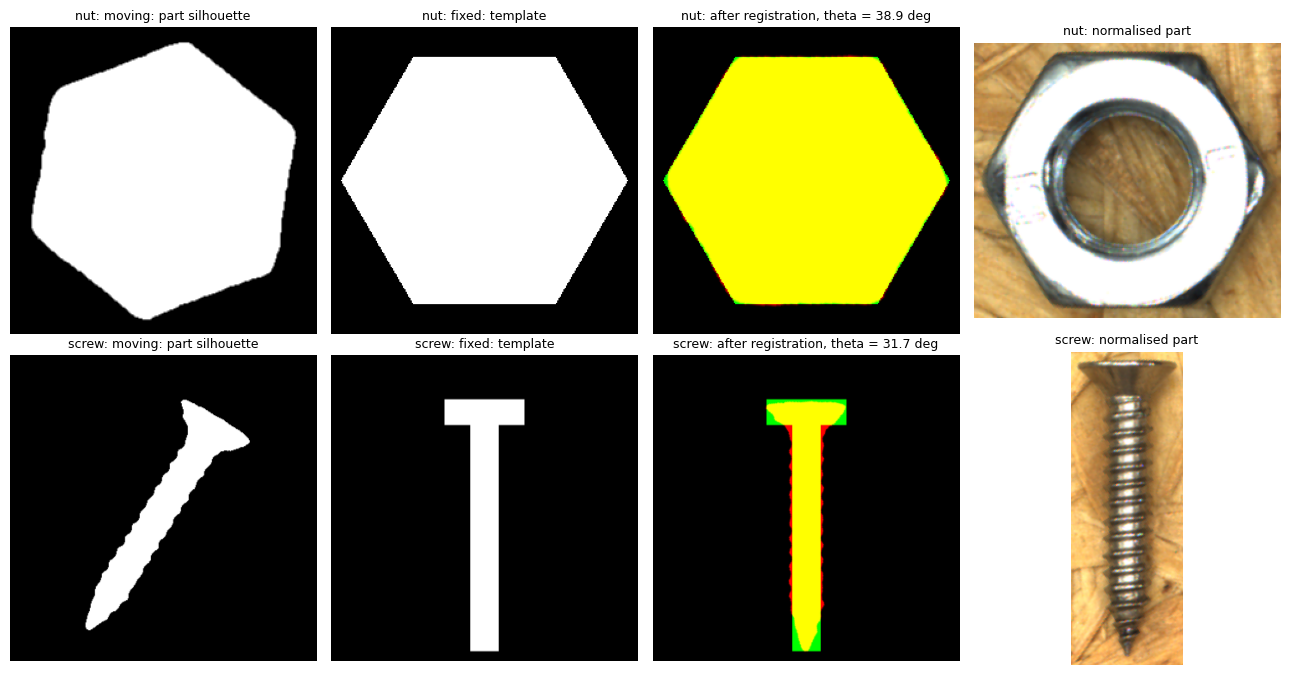

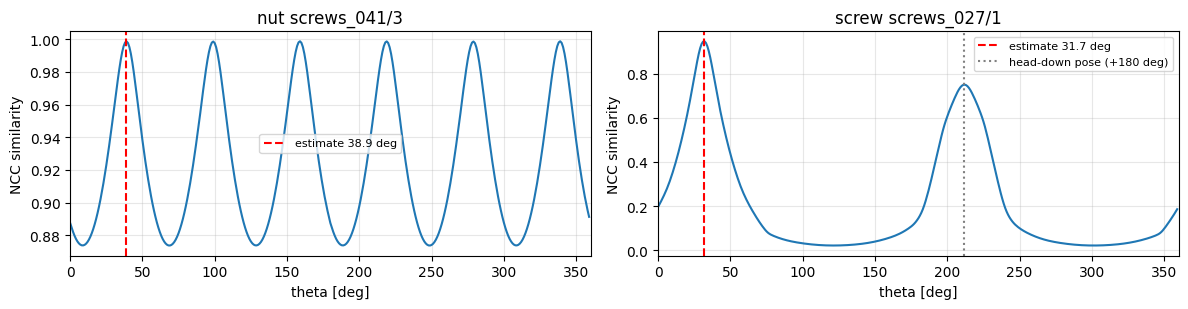

In [10]:
annotated = sorted({p.name for p in ANNOTATIONS_DIR.glob("*_labels.png")})
annotated_stems = [n.replace("_labels.png", "") for n in annotated]

# demo parts: the largest nut and a typical (median-size) screw among the annotated images
candidates = [p for p in image_paths if p.stem in annotated_stems] or image_paths[:5]
pool = {"nut": [], "screw": []}
for img_path in candidates:
    img = cv2.imread(str(img_path))
    labels, _ = load_labels(img_path, img)
    types = load_types(img_path.stem, labels)
    for r in measure.regionprops(labels.astype(np.int32)):
        pool[types[r.label][0]].append((r.area, img_path, r.label))
demo = []
for t, pick in (("nut", lambda L: L[-1]), ("screw", lambda L: L[len(L) // 2])):
    if pool[t]:
        _, img_path, pid = pick(sorted(pool[t], key=lambda x: x[0]))
        img = cv2.imread(str(img_path))
        demo.append((img_path, img, load_labels(img_path, img)[0], pid, t))

fig, axes = plt.subplots(len(demo), 4, figsize=(13, 3.4 * len(demo)), squeeze=False)
for row, (img_path, img, labels, pid, ptype) in enumerate(demo):
    r = normalise_part(img, labels, pid, ptype)
    overlay = np.dstack([rotate_canvas(r["canvas"], r["theta"]), r["fixed"], np.zeros_like(r["fixed"])])
    panels = [(r["canvas"], "moving: part silhouette"), (r["fixed"], "fixed: template"),
              (overlay, f"after registration, theta = {r['theta']:.1f} deg"),
              (cv2.cvtColor(r["rgb"], cv2.COLOR_BGR2RGB), "normalised part")]
    for ax, (im, title) in zip(axes[row], panels):
        ax.imshow(im, cmap="gray")
        ax.set_title(f"{ptype}: {title}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "c4-method.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(demo), figsize=(6 * len(demo), 3.2), squeeze=False)
for ax, (img_path, img, labels, pid, ptype) in zip(axes[0], demo):
    r = normalise_part(img, labels, pid, ptype)
    thetas, s = r["reg"].curve(360.0, 1.0, coarse=False)
    ax.plot(thetas, s, lw=1.5)
    ax.axvline(r["theta"], color="r", ls="--", label=f"estimate {r['theta']:.1f} deg")
    if ptype == "screw":
        ax.axvline((r["theta"] + 180) % 360, color="gray", ls=":", label="head-down pose (+180 deg)")
    ax.set(xlabel="theta [deg]", ylabel="NCC similarity", title=f"{ptype} {img_path.stem}/{pid}", xlim=(0, 360))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "c4-cost-curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Normalise every part of every image

Loop over **all** images in `inputs/`, register every part, and save each normalised part as
`outputs/challenge_4_results/parts/<image>_part<id>_<type>.png`. A table with the angle, the final similarity and
(for screws) the peak ratio is saved as `registration_results.csv`.

In [11]:
paths = image_paths if MAX_IMAGES is None else image_paths[:MAX_IMAGES]
records, store = [], {}            # store: normalised parts of annotated images (used by the checks below)
t0 = time.time()
for i, img_path in enumerate(paths):
    img = cv2.imread(str(img_path))
    labels, label_src = load_labels(img_path, img)
    types = load_types(img_path.stem, labels)
    for r in measure.regionprops(labels.astype(np.int32)):
        if r.area < MIN_PART_AREA:
            continue
        ptype, type_src = types[r.label]
        res = normalise_part(img, labels, r.label, ptype)
        fname = f"{img_path.stem}_part{r.label:02d}_{ptype}.png"
        cv2.imwrite(str(PARTS_DIR / fname), res["rgb"])
        records.append({"image": img_path.name, "part_id": r.label, "type": ptype, "type_source": type_src,
                         "label_source": label_src, "theta_deg": round(res["theta"], 3),
                         "similarity": round(res["score"], 4), "peak_ratio": round(res["ratio"], 4),
                         "file": fname})
        if img_path.stem in annotated_stems:
            store[(img_path.stem, r.label)] = dict(res, type=ptype)
    if (i + 1) % 20 == 0 or i + 1 == len(paths):
        print(f"{i + 1}/{len(paths)} images, {len(records)} parts, {time.time() - t0:.0f} s")

results = pd.DataFrame(records)
results.to_csv(OUT_DIR / "registration_results.csv", index=False)
print(results["label_source"].value_counts().to_string())
print(results["type"].value_counts().to_string())
results.head()

10/10 images, 86 parts, 38 s
label_source
C1-fallback    86
type
screw    60
nut      26


,image,part_id,type,type_source,label_source,theta_deg,similarity,peak_ratio,file
0,screws_026.png,1,screw,C2-rule,C1-fallback,18.194,0.9110,1.2184,screws_026_part01_screw.png
1,screws_026.png,2,screw,C2-rule,C1-fallback,128.360,0.9309,1.3086,screws_026_part02_screw.png
2,screws_026.png,3,screw,C2-rule,C1-fallback,284.885,0.9455,1.2595,screws_026_part03_screw.png
3,screws_026.png,4,nut,C2-rule,C1-fallback,38.827,0.9921,NaN,screws_026_part04_nut.png
4,screws_026.png,5,nut,C2-rule,C1-fallback,4.746,0.9905,NaN,screws_026_part05_nut.png


## 5. Mosaic of the normalised parts

Every normalised part is shrunk into a fixed cell (display only; the saved part images keep their real size).
Screws on top (head up), nuts below (flat side horizontal). `mosaic.jpg` contains all parts of all images;
`figures/c4-mosaic.png` only the annotated images (for the report).

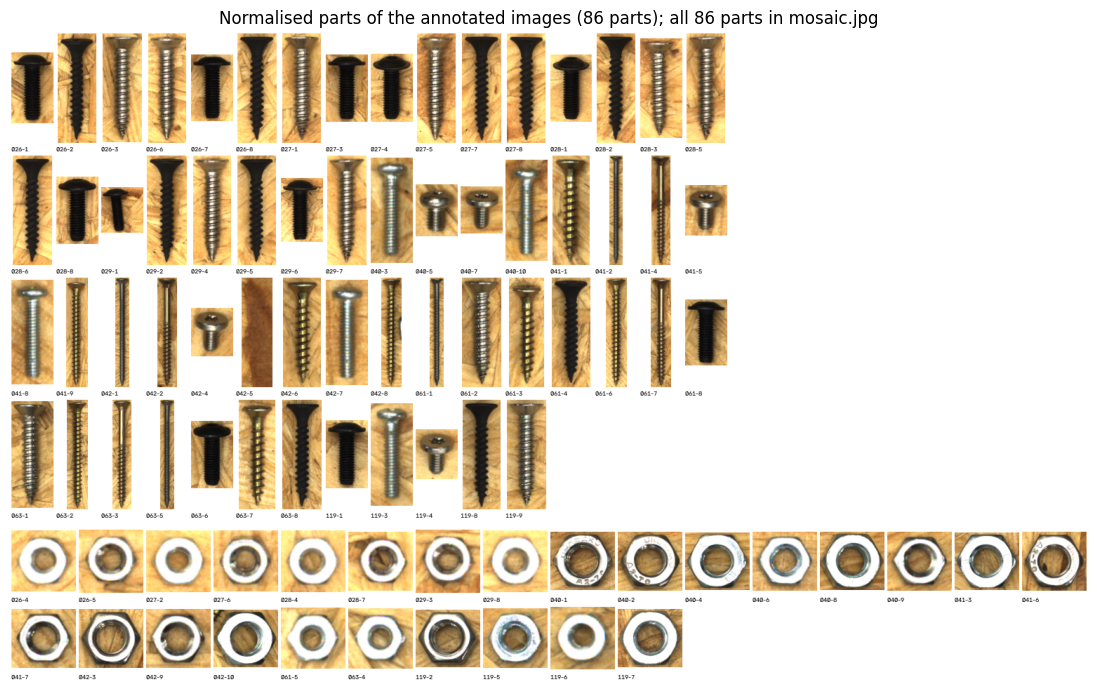

In [12]:
def build_mosaic(items, cols=16, cell_screw=(64, 160), cell_nut=(96, 96)):
    # items: list of (bgr_image, type, caption). Returns one BGR mosaic (screws block above nuts block).
    blocks = []
    for ptype, (cw, ch) in (("screw", cell_screw), ("nut", cell_nut)):
        sel = [it for it in items if it[1] == ptype]
        if not sel:
            continue
        rows = int(np.ceil(len(sel) / cols))
        block = np.full((rows * (ch + 14), cols * cw, 3), 255, np.uint8)
        for k, (im, _, cap) in enumerate(sel):
            h, w = im.shape[:2]
            s = min((cw - 4) / w, (ch - 4) / h)
            small = cv2.resize(im, (max(1, int(w * s)), max(1, int(h * s))), interpolation=cv2.INTER_AREA)
            r0, c0 = (k // cols) * (ch + 14), (k % cols) * cw
            y, x = r0 + (ch - small.shape[0]) // 2, c0 + (cw - small.shape[1]) // 2
            block[y:y + small.shape[0], x:x + small.shape[1]] = small
            cv2.putText(block, cap, (c0 + 2, r0 + ch + 10), cv2.FONT_HERSHEY_SIMPLEX, 0.28, (0, 0, 0), 1, cv2.LINE_AA)
        blocks.append(block)
    width = max(b.shape[1] for b in blocks)
    blocks = [np.pad(b, ((0, 10), (0, width - b.shape[1]), (0, 0)), constant_values=255) for b in blocks]
    return np.vstack(blocks)

all_items = []
for rec in records:
    im = cv2.imread(str(PARTS_DIR / rec["file"]))
    all_items.append((im, rec["type"], f"{Path(rec['image']).stem[-3:]}-{rec['part_id']}"))
mosaic_all = build_mosaic(all_items, cols=30 if len(all_items) > 300 else 16)
cv2.imwrite(str(OUT_DIR / "mosaic.jpg"), mosaic_all, [cv2.IMWRITE_JPEG_QUALITY, 90])

ann_items = [it for it, rec in zip(all_items, records) if Path(rec["image"]).stem in annotated_stems]
mosaic_ann = build_mosaic(ann_items if ann_items else all_items)
cv2.imwrite(str(FIG_DIR / "c4-mosaic.png"), mosaic_ann)

plt.figure(figsize=(14, 14 * mosaic_ann.shape[0] / mosaic_ann.shape[1]))
plt.imshow(cv2.cvtColor(mosaic_ann, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Normalised parts of the annotated images ({len(ann_items)} parts); all {len(all_items)} parts in mosaic.jpg")
plt.show()

## 6. Independent verification on the real poses (annotated images)

The error must be measured with something the estimator does **not** use:
* **Nuts: Hough lines.** Edges of the normalised nut, `cv2.HoughLines`, take the 6 strongest lines. A hexagon has sides
  every 60 deg, so each line angle is folded into (-30, 30] deg; the median is the residual: 0 means a side is exactly horizontal.
* **Screws: principal axis.** Orientation of the normalised silhouette from its second-order moments, compared with vertical.
* **Screws: head on top.** The head point annotated by hand (`head_x`, `head_y` in `parts.csv`) is pushed through the
  estimated transformation. Correct if it ends up above the centroid.

Detected parts are matched to annotated parts by IoU >= 0.5 (Hungarian assignment), because C1 numbers parts differently.

In [13]:
parts_csv = pd.read_csv(ANNOTATIONS_DIR / "parts.csv")

def hough_residual_nut(mask):
    edges = cv2.Canny(mask.astype(np.uint8) * 255, 50, 150)
    R = np.sqrt(2.0 * mask.sum() / (3.0 * np.sqrt(3.0)))
    lines = None
    for frac in (0.6, 0.45, 0.3):                       # lower the vote threshold if too few lines
        lines = cv2.HoughLines(edges, 1, np.pi / 720, threshold=max(10, int(frac * R)))
        if lines is not None and len(lines) >= 3:
            break
    if lines is None:
        return np.nan, None
    lines = lines[:6, 0, :]                             # strongest first
    direction = np.rad2deg(lines[:, 1]) - 90.0          # HoughLines gives the normal angle; line = normal - 90
    return float(np.median([wrap(d, 60.0) for d in direction])), lines

def axis_residual_screw(mask):
    m = cv2.moments(mask.astype(np.float32))
    ang = 0.5 * np.degrees(np.arctan2(2 * m["mu11"], m["mu20"] - m["mu02"]))   # major axis vs x axis
    return float(wrap(ang - 90.0, 180.0))

def match_to_gt(pred, gt, min_iou=0.5):
    p_ids, g_ids = [i for i in np.unique(pred) if i], [j for j in np.unique(gt) if j]
    iou = np.zeros((len(p_ids), len(g_ids)))
    for a, i in enumerate(p_ids):
        pm = pred == i
        for b, j in enumerate(g_ids):
            gm = gt == j
            inter = np.logical_and(pm, gm).sum()
            if inter:
                iou[a, b] = inter / np.logical_or(pm, gm).sum()
    rows, cols = linear_sum_assignment(-iou)
    return {p_ids[a]: g_ids[b] for a, b in zip(rows, cols) if iou[a, b] >= min_iou}

checks = []
for stem in annotated_stems:
    img_path = next((p for p in paths if p.stem == stem), None)
    if img_path is None:
        continue
    pred = load_labels(img_path, cv2.imread(str(img_path)))[0]
    gt = cv2.imread(str(ANNOTATIONS_DIR / f"{stem}_labels.png"), cv2.IMREAD_UNCHANGED)
    matches = match_to_gt(pred, gt)
    for (s, pid), res in store.items():
        if s != stem:
            continue
        row = {"image": stem, "part_id": pid, "type": res["type"], "gt_part_id": matches.get(pid)}
        gt_row = parts_csv[(parts_csv["image"].str.replace(r"\.\w+$", "", regex=True) == stem)
                           & (parts_csv["part_id"] == row["gt_part_id"])]
        row["gt_type"] = gt_row["type"].iloc[0] if len(gt_row) else None
        if res["type"] == "nut":
            row["residual_deg"] = hough_residual_nut(res["mask_full"])[0]
        else:
            row["residual_deg"] = axis_residual_screw(res["mask_full"])
            if len(gt_row) and gt_row["type"].iloc[0] == "screw":
                hx, hy = gt_row[["head_x", "head_y"]].iloc[0]
                y_head = res["M"][1] @ np.array([hx, hy, 1.0])
                row["head_on_top"] = bool(y_head < (res["S"] - 1) / 2.0)
        checks.append(row)

checks = pd.DataFrame(checks)
checks.to_csv(OUT_DIR / "verification_real_poses.csv", index=False)
print("type disagreements with annotation:", int((checks["gt_type"].notna() & (checks["gt_type"] != checks["type"])).sum()))
for t in ("nut", "screw"):
    e = checks.loc[checks["type"] == t, "residual_deg"].abs().dropna()
    print(f"{t:5s} n={len(e):3d}  |residual| mean {e.mean():.2f}  median {e.median():.2f}  P95 {e.quantile(.95):.2f}  max {e.max():.2f} deg")
h = checks["head_on_top"].dropna() if "head_on_top" in checks else pd.Series(dtype=bool)
print(f"screws with head on top: {int(h.sum())}/{len(h)}")

type disagreements with annotation: 0
nut   n= 26  |residual| mean 0.80  median 0.44  P95 2.09  max 4.38 deg
screw n= 60  |residual| mean 0.31  median 0.12  P95 1.22  max 3.02 deg
screws with head on top: 59/59


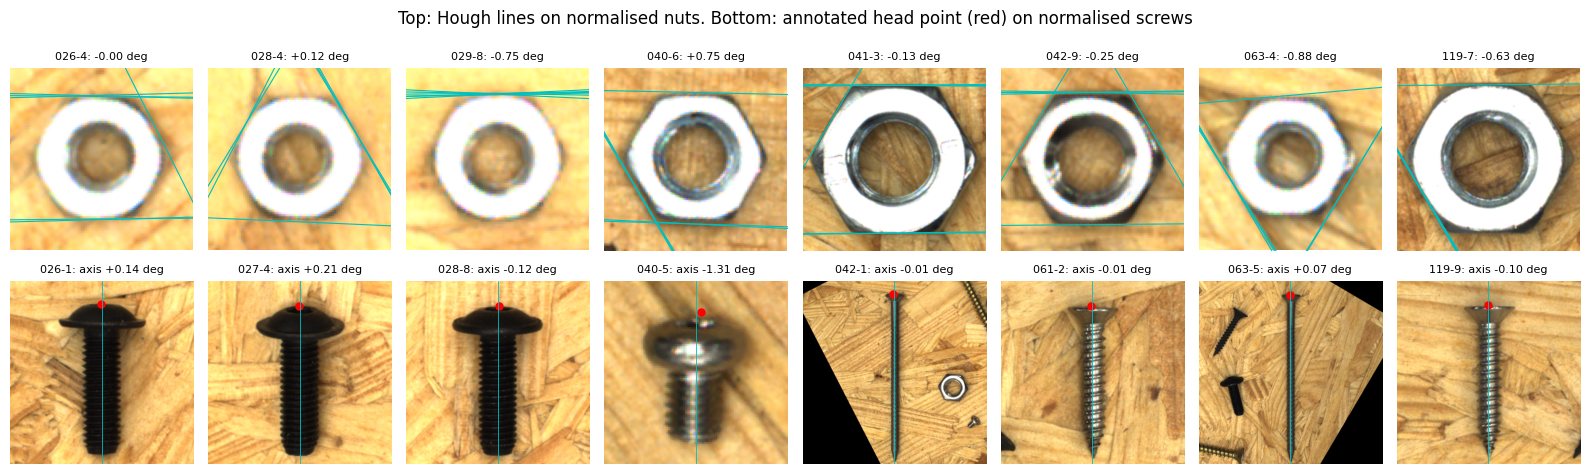

In [14]:
# Figure: normalised nuts with their Hough lines, normalised screws with the annotated head point
def spread(keys, n=8):   # n parts spread over all annotated images
    return [keys[i] for i in np.unique(np.linspace(0, len(keys) - 1, n).round().astype(int))] if keys else []
nut_keys = spread([k for k, v in store.items() if v["type"] == "nut"])
screw_keys = spread([k for k, v in store.items() if v["type"] == "screw"])
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax, k in zip(axes[0], nut_keys):
    res = store[k]
    resid, lines = hough_residual_nut(res["mask_full"])
    ax.imshow(cv2.cvtColor(cv2.warpAffine(cv2.imread(str(INPUT_DIR / next(p.name for p in paths if p.stem == k[0]))),
                                          res["M"], (res["S"], res["S"])), cv2.COLOR_BGR2RGB))
    if lines is not None:
        for rho, th in lines:
            a, b = np.cos(th), np.sin(th)
            x0, y0 = a * rho, b * rho
            ax.plot([x0 - 1000 * b, x0 + 1000 * b], [y0 + 1000 * a, y0 - 1000 * a], "c-", lw=0.8)
    ax.set_xlim(0, res["S"]); ax.set_ylim(res["S"], 0)
    ax.set_title(f"{k[0][-3:]}-{k[1]}: {resid:+.2f} deg", fontsize=8)
for ax, k in zip(axes[1], screw_keys):
    res = store[k]
    ax.imshow(cv2.cvtColor(cv2.warpAffine(cv2.imread(str(INPUT_DIR / next(p.name for p in paths if p.stem == k[0]))),
                                          res["M"], (res["S"], res["S"])), cv2.COLOR_BGR2RGB))
    row = checks[(checks["image"] == k[0]) & (checks["part_id"] == k[1])]
    g = parts_csv[(parts_csv["image"].str.startswith(k[0])) & (parts_csv["part_id"] == row["gt_part_id"].iloc[0])] if len(row) else []
    if len(g):
        hx, hy = res["M"] @ np.array([g["head_x"].iloc[0], g["head_y"].iloc[0], 1.0])
        ax.plot(hx, hy, "ro", ms=5)
    ax.axvline((res["S"] - 1) / 2, color="c", lw=0.6)
    ax.set_title(f"{k[0][-3:]}-{k[1]}: axis {axis_residual_screw(res['mask_full']):+.2f} deg", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Top: Hough lines on normalised nuts. Bottom: annotated head point (red) on normalised screws")
plt.tight_layout()
plt.savefig(FIG_DIR / "c4-hough-check.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Test on known rotations and dependence on the initial guess

**Known rotations.** Each part in the annotated images is rotated by known angles alpha = 7, 37, 67, ... , 337 deg, totalling 12 angles, which are deliberately not multiples of the grid step, and the estimate is repeated. If the method is consistent,
the new estimate must equal the old one minus alpha, so the error is
`e = wrap(theta(alpha) + alpha - theta(0))`, wrapped with period 60 deg (nuts) or 360 deg (screws).
For screws, |e| close to 180 deg is a head/tip flip.

**Initial guess.** To show why we use a global grid, we also run a purely local optimiser of Nelder-Mead starting from
theta* + delta for delta = -180 to 180 deg and record where it ends, which might give one of these results: Corect pose (mod the symmetry), head-down pose (screws), or somewhere else.

In [15]:
ALPHAS = np.arange(7.0, 360.0, 30.0)

def estimate(canvas, ptype):
    p = shape_params(canvas)
    reg = Registration(canvas, make_template(ptype, p, canvas.shape[0]))
    return reg.solve(PERIOD[ptype])[0]

known = []
t0 = time.time()
for (stem, pid), res in store.items():
    P = PERIOD[res["type"]]
    theta0 = res["theta"]
    for a in ALPHAS:
        rotated = (rotate_canvas(res["canvas"], a) > 0.5).astype(np.float32)   # part rotated by a known angle
        e = wrap(estimate(rotated, res["type"]) + a - theta0, P)
        known.append({"image": stem, "part_id": pid, "type": res["type"], "alpha": a, "error_deg": e})
known = pd.DataFrame(known)
known.to_csv(OUT_DIR / "known_rotation_test.csv", index=False)
print(f"{len(known)} runs in {time.time() - t0:.0f} s")
for t in ("nut", "screw"):
    k = known[known["type"] == t]
    flips = (k["error_deg"].abs() > 90).sum() if t == "screw" else 0
    e = k.loc[k["error_deg"].abs() <= 90, "error_deg"].abs()
    print(f"{t:5s} runs={len(k):4d}  |e| mean {e.mean():.2f}  median {e.median():.2f}  P95 {e.quantile(.95):.2f}  "
          f"max {e.max():.2f} deg   head flips: {flips}")

1032 runs in 83 s
nut   runs= 312  |e| mean 0.19  median 0.08  P95 0.71  max 1.70 deg   head flips: 0
screw runs= 720  |e| mean 0.06  median 0.01  P95 0.15  max 1.86 deg   head flips: 0


In [16]:
DELTAS = np.arange(-180.0, 181.0, 10.0)
init = []
for (stem, pid), res in store.items():
    P = PERIOD[res["type"]]
    reg = res["reg"]
    t_star = res["theta"]
    for d in DELTAS:
        x0 = t_star + d
        out = minimize(lambda t: -reg.similarity(t[0], coarse=True), x0=[x0], method="Nelder-Mead",
                       options={"xatol": 0.1, "fatol": 1e-6, "initial_simplex": [[x0], [x0 + 5.0]]})
        err = wrap(out.x[0] - t_star, P)
        if abs(err) <= 2.0:
            outcome = "correct"
        elif res["type"] == "screw" and abs(wrap(err - 180.0, 360.0)) <= 2.0:
            outcome = "head down"
        else:
            outcome = "other local optimum"
        init.append({"type": res["type"], "delta": d, "outcome": outcome})
init = pd.DataFrame(init)
init.to_csv(OUT_DIR / "initial_guess_test.csv", index=False)
print(init.groupby(["type", "outcome"]).size().to_string())

type   outcome            
nut    correct                 962
screw  correct                1081
       head down              1063
       other local optimum      76


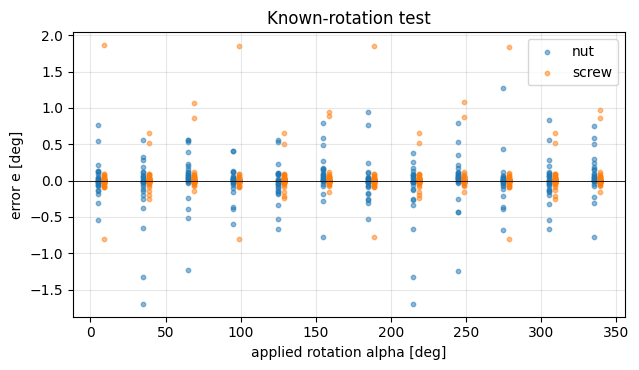

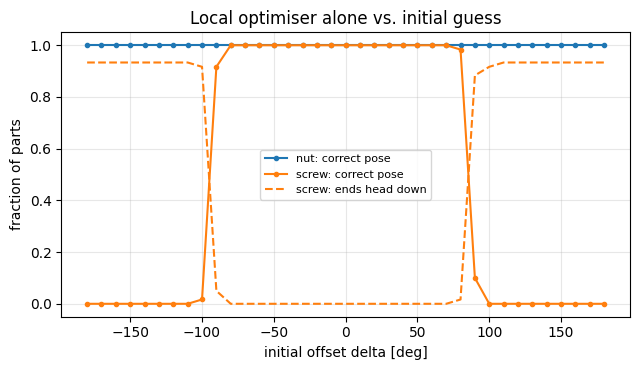

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for t, c in (("nut", "tab:blue"), ("screw", "tab:orange")):
    k = known[known["type"] == t]
    ax.scatter(k["alpha"] + (2 if t == "screw" else -2), k["error_deg"], s=10, alpha=0.5, color=c, label=t)
ax.set(xlabel="applied rotation alpha [deg]", ylabel="error e [deg]", title="Known-rotation test")
ax.axhline(0, color="k", lw=0.6)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "c4-known-angles.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for t, c in (("nut", "tab:blue"), ("screw", "tab:orange")):
    k = init[init["type"] == t]
    rate = k.groupby("delta")["outcome"].apply(lambda o: (o == "correct").mean())
    ax.plot(rate.index, rate.values, "-o", ms=3, color=c, label=f"{t}: correct pose")
    if t == "screw":
        flip = k.groupby("delta")["outcome"].apply(lambda o: (o == "head down").mean())
        ax.plot(flip.index, flip.values, "--", color=c, label="screw: ends head down")
ax.set(xlabel="initial offset delta [deg]", ylabel="fraction of parts",
       title="Local optimiser alone vs. initial guess", ylim=(-0.05, 1.05))
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "c4-init-guess.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Summary for the report



In [18]:
def stats(e):
    e = pd.Series(e).abs().dropna()
    return pd.Series({"n": len(e), "mean": e.mean(), "median": e.median(), "P95": e.quantile(.95), "max": e.max()})

kn, ks = known[known["type"] == "nut"], known[known["type"] == "screw"]
summary = pd.DataFrame({
    "Nuts, real poses (Hough)": stats(checks.loc[checks["type"] == "nut", "residual_deg"]),
    "Screws, real poses (moment axis)": stats(checks.loc[checks["type"] == "screw", "residual_deg"]),
    "Nuts, known rotations (mod 60)": stats(kn["error_deg"]),
    "Screws, known rotations (no flips)": stats(ks.loc[ks["error_deg"].abs() <= 90, "error_deg"]),
}).T.round(2)
summary["n"] = summary["n"].astype(int)
display(summary)

h = checks["head_on_top"].dropna() if "head_on_top" in checks else pd.Series(dtype=bool)
print(f"Head on top (annotated head point): {int(h.sum())}/{len(h)} = {100 * h.mean():.1f} %")
print(f"Head flips in known-rotation test : {int((ks['error_deg'].abs() > 90).sum())}/{len(ks)}"
      f" = {100 * (ks['error_deg'].abs() > 90).mean():.1f} %")
pr = results.loc[results["type"] == "screw", "peak_ratio"]
print(f"Screw peak ratio S(head up)/S(head down): min {pr.min():.3f}, median {pr.median():.3f} (all images)")
print(f"Lowest similarity: nut {results.loc[results.type == 'nut', 'similarity'].min():.3f}, "
      f"screw {results.loc[results.type == 'screw', 'similarity'].min():.3f}")

,n,mean,median,P95,max
"Nuts, real poses (Hough)",26,0.80,0.44,2.09,4.38
"Screws, real poses (moment axis)",60,0.31,0.12,1.22,3.02
"Nuts, known rotations (mod 60)",312,0.19,0.08,0.71,1.70
"Screws, known rotations (no flips)",720,0.06,0.01,0.15,1.86


Head on top (annotated head point): 59/59 = 100.0 %
Head flips in known-rotation test : 0/720 = 0.0 %
Screw peak ratio S(head up)/S(head down): min 1.046, median 1.215 (all images)
Lowest similarity: nut 0.966, screw 0.680
